In [1]:
%pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 103.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [medmnist]3/6 [scikit-image]
Note: you may need to restart the kernel to use updated packages.


In [2]:
# downloads all three sizes
from medmnist import PathMNIST
DATA = "/home/ec2-user/SageMaker/data"

# split="test" downloads the full file (all splits) but only loads the small
# test set into memory. The 224 training set alone would need ~13.5 GB of RAM.
for size in [64, 128, 224]:
    print(f"--- {size}x{size} ---")
    PathMNIST(split="test", download=True, size=size, root=DATA)

--- 64x64 ---
--- 128x128 ---
--- 224x224 ---


100%|██████████| 12.6G/12.6G [51:36<00:00, 4.08MB/s]  


In [3]:
# shows what landed on disk
!ls -lh /home/ec2-user/SageMaker/data

total 17G
-rw-r--r--. 1 ec2-user ec2-user  4.0G Nov  2 07:56 pathmnist_128.npz
-rw-r--r--. 1 ec2-user ec2-user   12G Nov  2 18:58 pathmnist_224.npz
-rw-r--r--. 1 ec2-user ec2-user 1020M Nov  2 07:32 pathmnist_64.npz


{'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}
train 89996
val 10004
test 7180


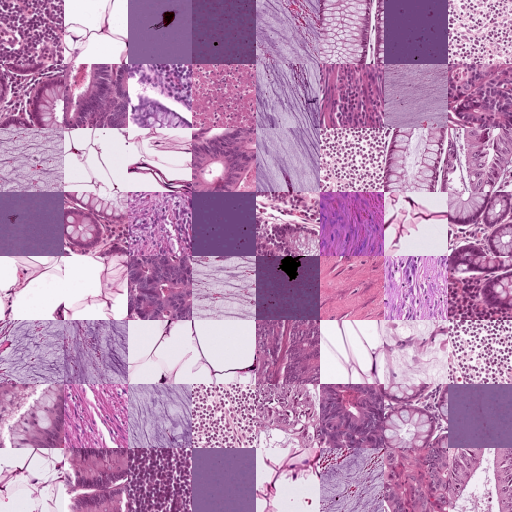

In [4]:
# checks the data at 64×64
from medmnist import INFO
print(INFO["pathmnist"]["label"])          # the 9 tissue classes

for split in ["train", "val", "test"]:
    ds = PathMNIST(split=split, size=64, root=DATA)
    print(split, len(ds))

ds.montage(length=8)                       # 8x8 grid of sample patches

# You should see 89996 train, 10004 val, and 7180 test, followed by a grid of tissue images.